<a href="https://colab.research.google.com/github/guptaekta159/yulu_business_analysis/blob/main/yulu_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro,levene
from scipy.stats import probplot


In [5]:
#  it represents of load of data

In [6]:

df=pd.read_csv("/content/bike_sharing.txt")

In [7]:




# it shows first two rows

In [8]:
df.head(2)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40


In [9]:
# it shows all columns non null values and their data types

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [11]:
#  it shows the shape of the dataframe it represents of no of rows and columns

In [12]:
df.shape

(10886, 12)

In [13]:
# it gives all the information of statistical summary of the dataset

In [14]:
df.describe(include="number")

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


In [15]:
#  it shows null values of the dataset

In [16]:
df.isnull().sum()

,0
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,0


In [17]:
#  it converts the datatype to another datatype

In [18]:
df["datetime"]=pd.to_datetime(df["datetime"],errors="coerce")
df["season"]=df["season"].astype("object")
df["holiday"]=df["holiday"].astype("object")
df["workingday"]=df["workingday"].astype("object")
df["weather"]=df["weather"].astype("object")

In [19]:
#  it represents how many duplicated values present in the dataset

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
#  univariate analysis

In [22]:
df.columns.tolist()

['datetime',
 'season',
 'holiday',
 'workingday',
 'weather',
 'temp',
 'atemp',
 'humidity',
 'windspeed',
 'casual',
 'registered',
 'count']

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[ns]
 1   season      10886 non-null  object        
 2   holiday     10886 non-null  object        
 3   workingday  10886 non-null  object        
 4   weather     10886 non-null  object        
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(4), object(4)
memory usage: 1020.7+ KB


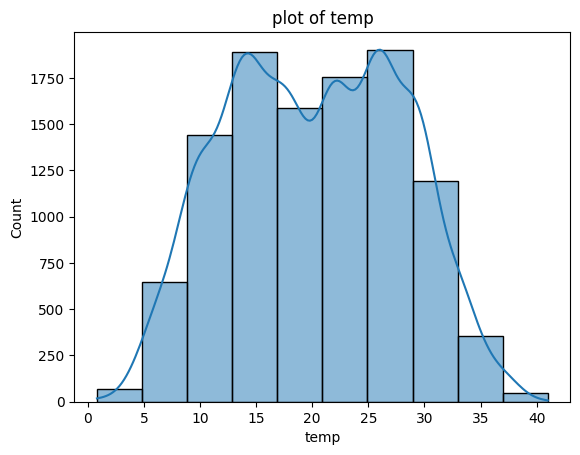

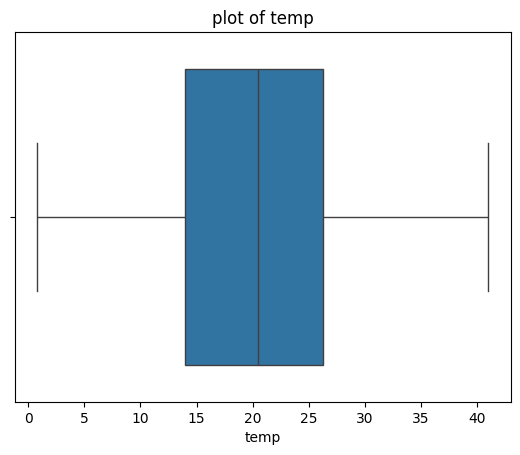

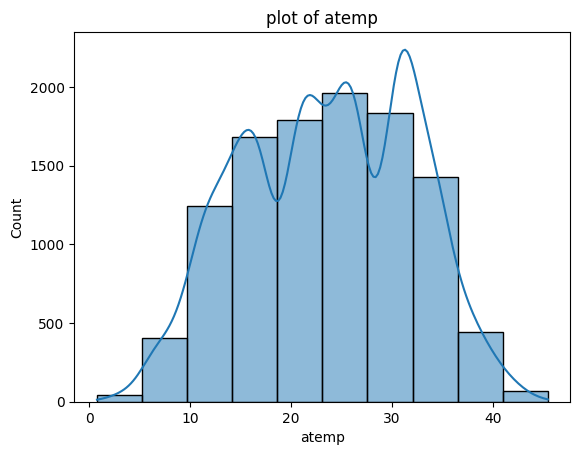

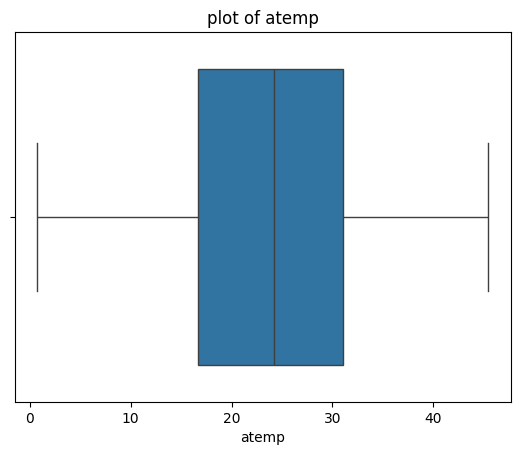

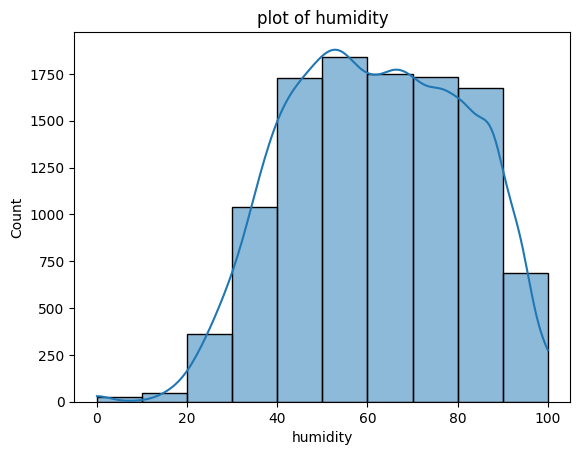

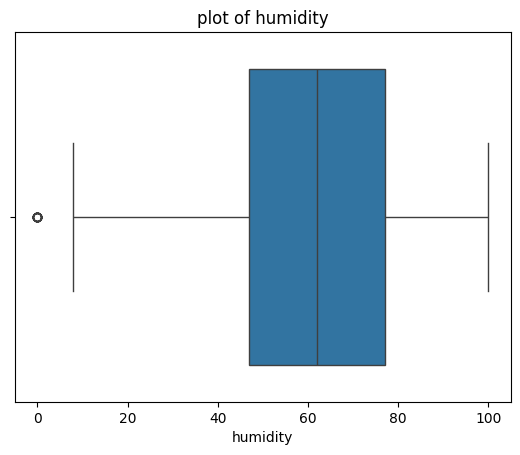

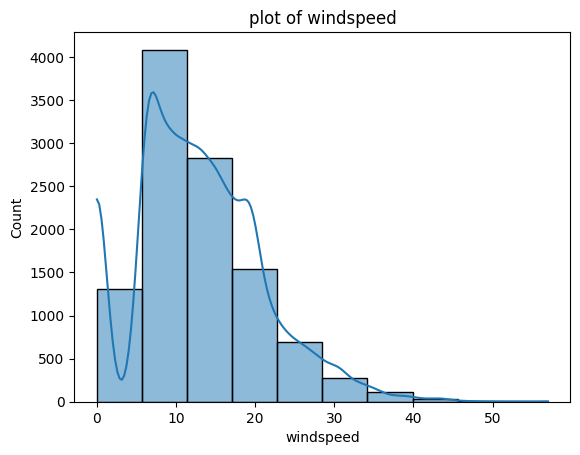

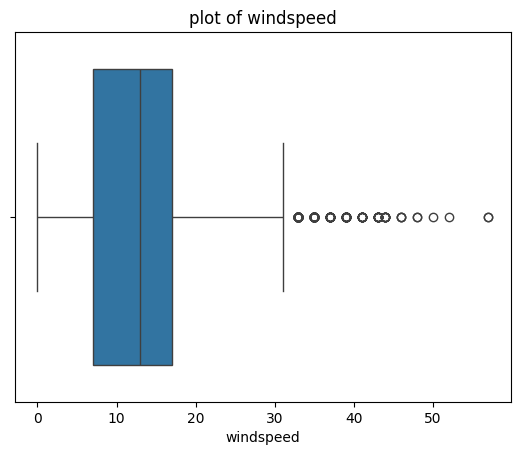

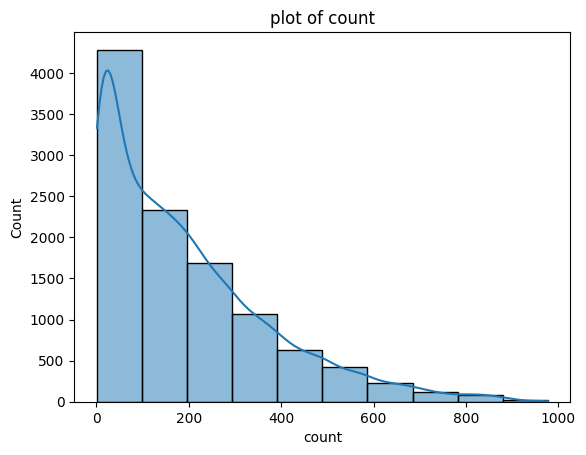

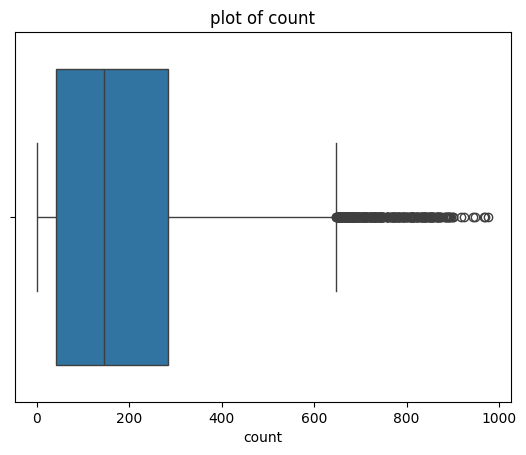

In [24]:
cols=df.select_dtypes(include="number")[["temp","atemp","humidity","windspeed","count"]]
for i in cols:
 sns.histplot(x=df[i],data=df,bins=10,kde=True)
 plt.title(f"plot of {i}")
 plt.show()
 sns.boxplot(x=df[i],data=df)
 plt.title(f"plot of {i}")
 plt.show()


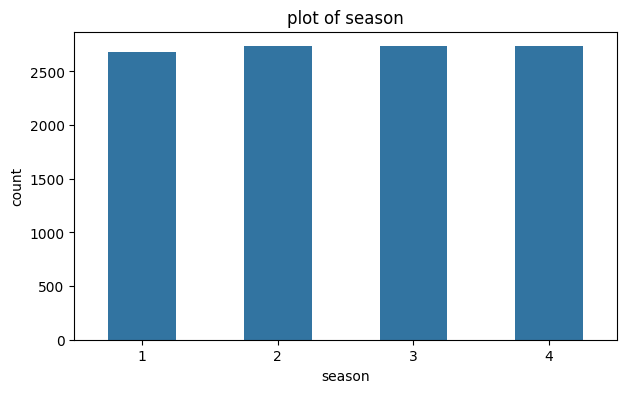

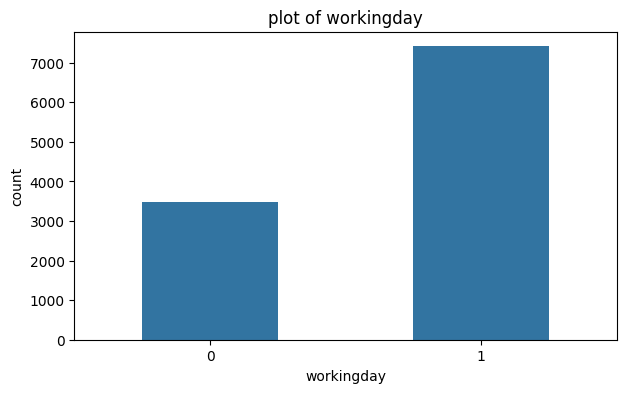

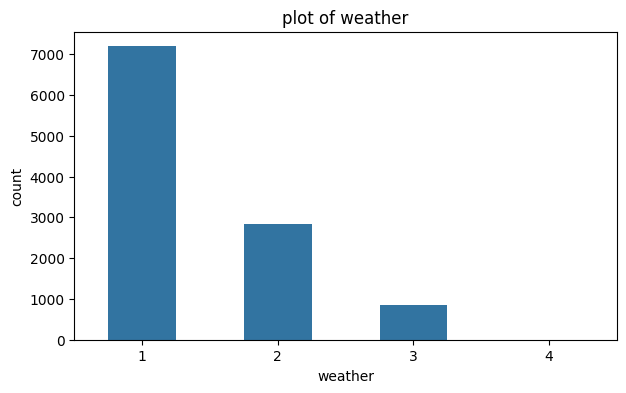

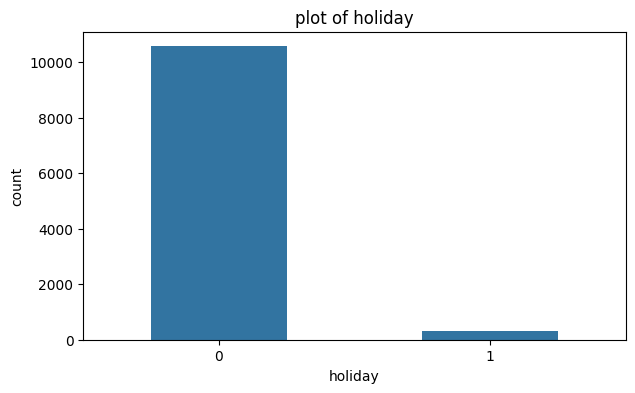

In [25]:
category_cols=df.select_dtypes(include="object")[["season","workingday","weather","holiday"]]
for i in category_cols:
  plt.figure(figsize=(7,4))
  sns.countplot(x=df[i],data=df,width=0.5)
  plt.title(f"plot of {i}")
  plt.show()

In [26]:
# bivariate analysis

<Axes: xlabel='season', ylabel='count'>

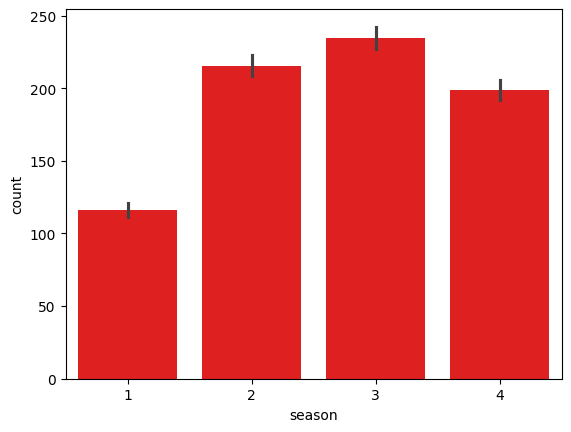

In [27]:
sns.barplot(x=df["season"],y=df["count"],data=df,color="red")

<Axes: xlabel='workingday', ylabel='count'>

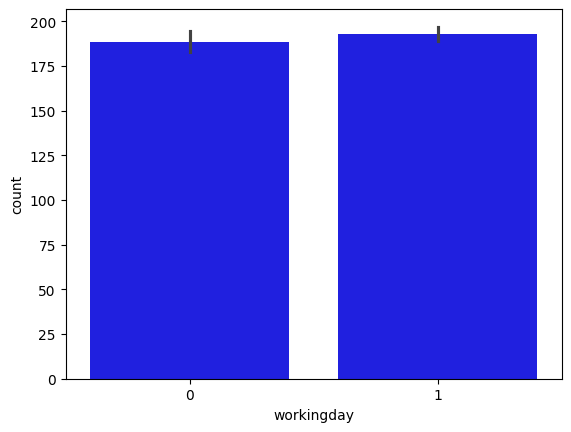

In [28]:
sns.barplot(x=df["workingday"],y=df["count"],data=df,color="blue")

<Axes: xlabel='holiday', ylabel='count'>

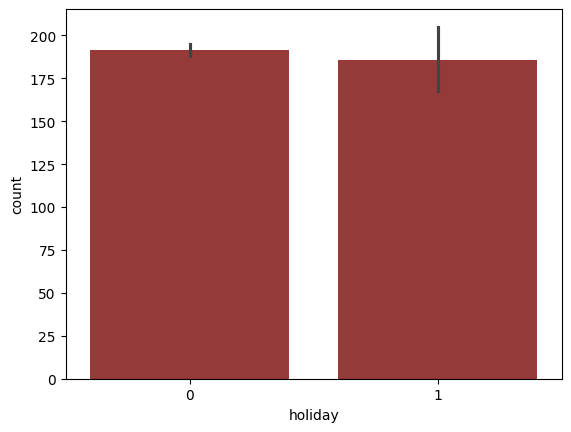

In [29]:
sns.barplot(x=df["holiday"],y=df["count"],data=df,color="brown")

<Axes: xlabel='weather', ylabel='count'>

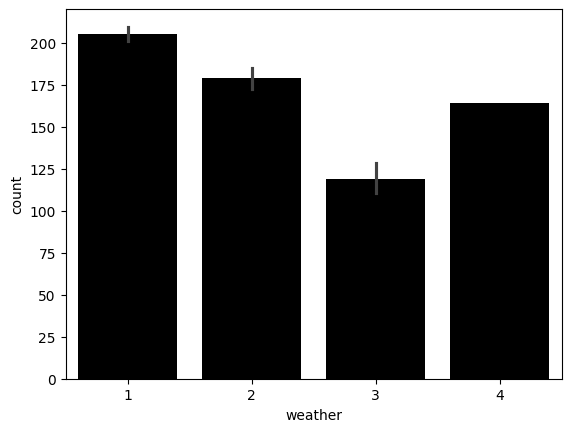

In [30]:
sns.barplot(x=df["weather"],y=df["count"],data=df,color="black")

In [31]:
cols=df.select_dtypes(include="number")[["temp","atemp","humidity","windspeed","count"]]
correlation=df.corr()

<Axes: >

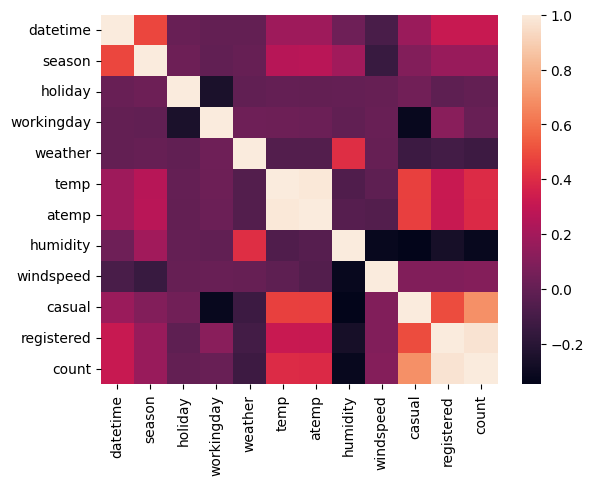

In [32]:
sns.heatmap(correlation)

In [33]:
# Select an appropriate test to check whether:
# Working Day has effect on number of electric cycles rented


In [34]:
no_working_day=df["count"][df["workingday"]==0]
working_day=df["count"][df["workingday"]==1]

In [35]:
#  normality check with the help of histogram,QQplot and Shapiro wilk test

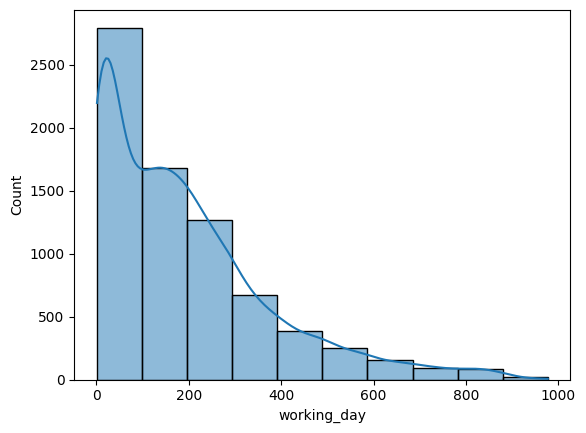

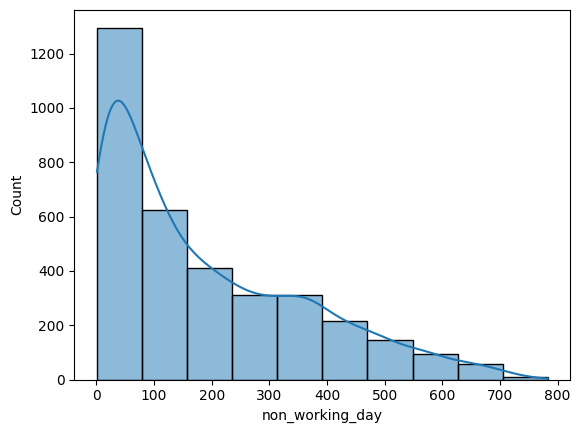

In [36]:
sns.histplot(working_day,bins=10,kde=True)
plt.xlabel("working_day")
plt.show()
sns.histplot(no_working_day,bins=10,kde=True)
plt.xlabel("non_working_day")
plt.show()

In [37]:
# QQ plot for working_day and non_working_day

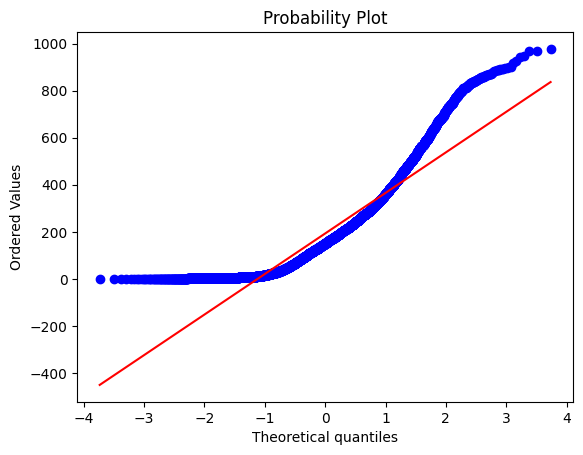

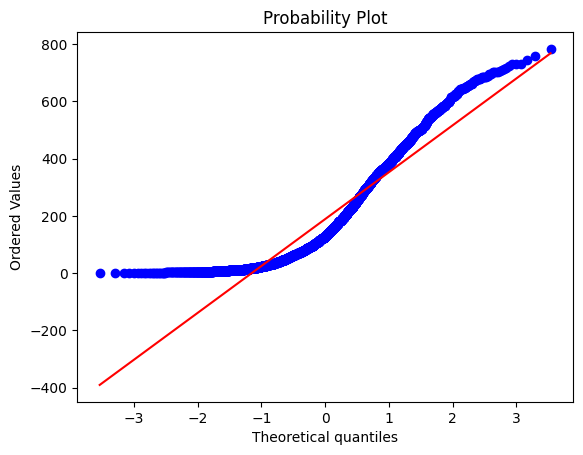

In [38]:
probplot(working_day,dist="norm",plot=plt)
plt.show()
probplot(no_working_day,dist="norm",plot=plt)
plt.show()

In [39]:
# H0=there is no significance difference between working_day and no_working_day of the no of rented cycle
# H1=there is  significance difference between working_day and no_working_day of the no of rented cycle

In [40]:
test_stats,p_value=shapiro(working_day)
p_value

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7412.
  res = hypotest_fun_out(*samples, **kwds)


np.float64(2.2521124830019574e-61)

In [41]:
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [42]:
# check the variance between working and non working day of the rented cycle

In [43]:
test_stats,p_value=levene(working_day,no_working_day)
p_value

np.float64(0.9437823280916695)

In [44]:
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

Not to reject the null hypothesis


In [45]:
# it means variance are equal

In [46]:
# due to normality fails we will use mannwhitneyu test instead of ttest_ind

In [47]:
from scipy.stats import mannwhitneyu

In [48]:
test_stats,p_value=mannwhitneyu(working_day,no_working_day)
p_value

np.float64(0.9679139953914079)

In [49]:
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

Not to reject the null hypothesis


In [50]:
# H0=there is no significance difference between working_day and no_working_day of the no of rented cycle

In [51]:
# No. of cycles rented similar or different in different seasons

In [52]:
# H0=there is no significance difference between working_day and no_working_day of the no of rented cycle
# H1=there is  significance difference between working_day and no_working_day of the no of rented cycle

In [53]:
season_1=df["count"][df["season"]==1]
season_2=df["count"][df["season"]==2]
season_3=df["count"][df["season"]==3]
season_4=df["count"][df["season"]==4]


In [54]:
#   normality check with the help of histogram,QQplot and Shapiro wilk test

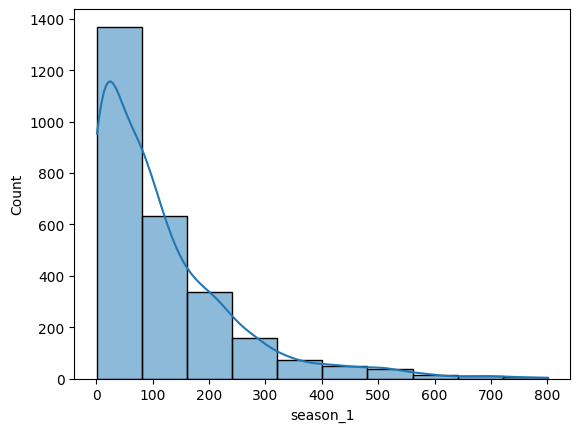

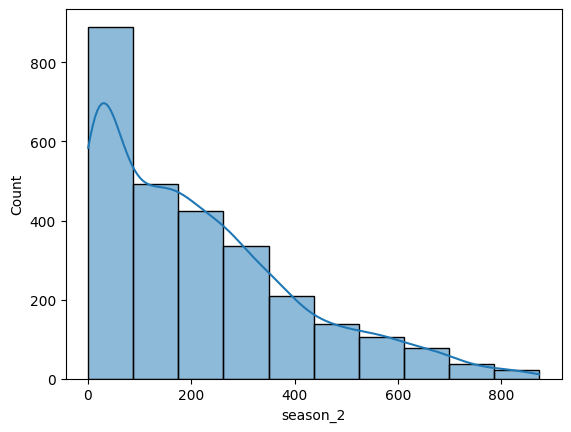

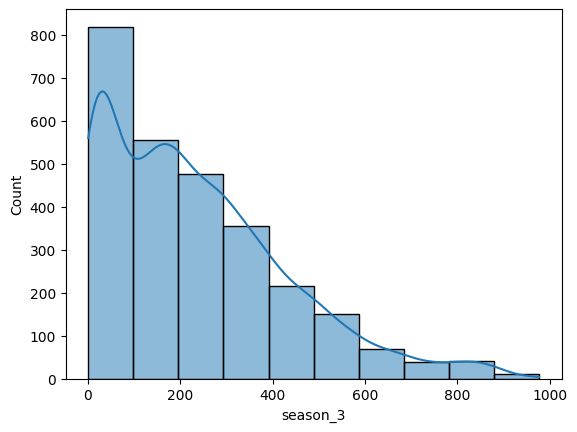

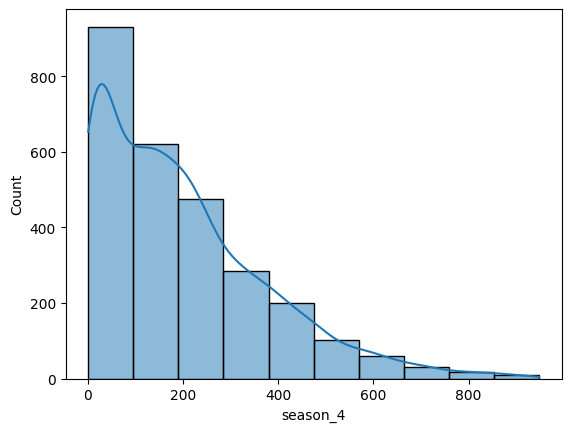

In [55]:
sns.histplot(season_1,bins=10,kde=True)
plt.xlabel("season_1")
plt.show()
sns.histplot(season_2,bins=10,kde=True)
plt.xlabel("season_2")
plt.show()
sns.histplot(season_3,bins=10,kde=True)
plt.xlabel("season_3")
plt.show()
sns.histplot(season_4,bins=10,kde=True)
plt.xlabel("season_4")
plt.show()

In [56]:
# check QQ plot for seasons

((array([-3.47228304, -3.22661884, -3.09065989, ...,  3.09065989,
          3.22661884,  3.47228304]),
  array([  1,   1,   1, ..., 749, 782, 801])),
 (np.float64(112.76736871266662),
  np.float64(116.34326135517497),
  np.float64(0.8992877915950637)))

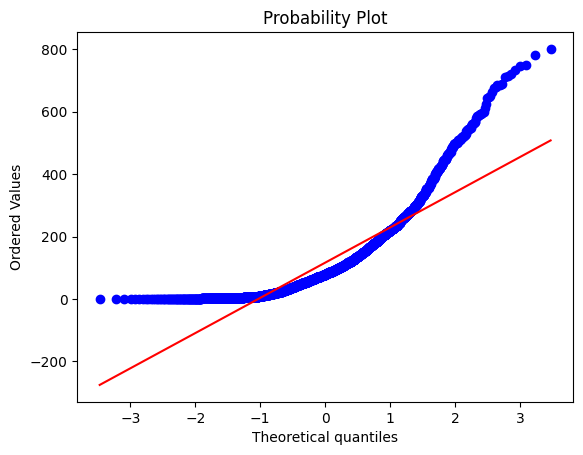

In [57]:
probplot(season_1,dist="norm",plot=plt)


((array([-3.47693624, -3.2315789 , -3.09580678, ...,  3.09580678,
          3.2315789 ,  3.47693624]),
  array([  1,   1,   1, ..., 868, 869, 873])),
 (np.float64(182.42737385795178),
  np.float64(215.25137211855102),
  np.float64(0.9491907117737892)))

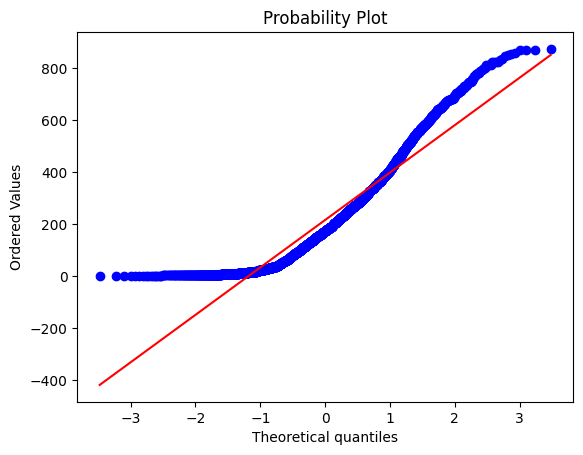

In [58]:
probplot(season_2,dist="norm",plot=plt)

((array([-3.47693624, -3.2315789 , -3.09580678, ...,  3.09580678,
          3.2315789 ,  3.47693624]),
  array([  1,   1,   1, ..., 968, 970, 977])),
 (np.float64(188.79033329815735),
  np.float64(234.41712403951698),
  np.float64(0.9566723243576185)))

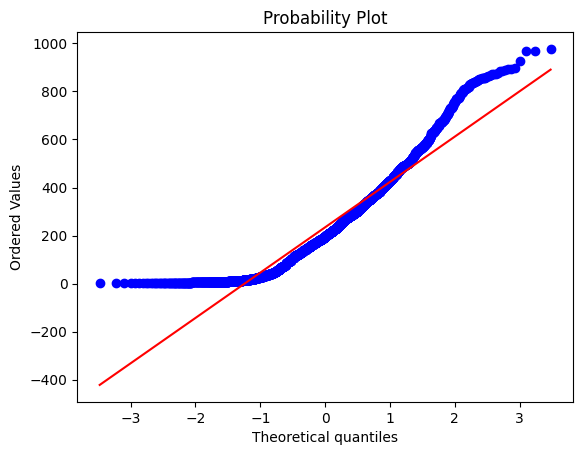

In [59]:
probplot(season_3,dist="norm",plot=plt)

((array([-3.47703432, -3.23168344, -3.09591525, ...,  3.09591525,
          3.23168344,  3.47703432]),
  array([  1,   1,   1, ..., 917, 943, 948])),
 (np.float64(168.27167256266733),
  np.float64(198.98829553767374),
  np.float64(0.9464459779766068)))

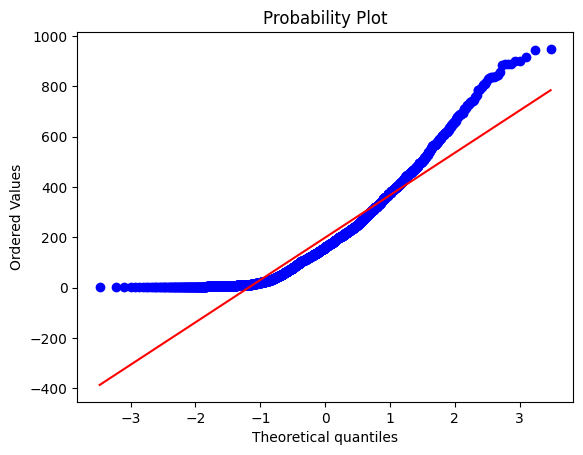

In [60]:
probplot(season_4,dist="norm",plot=plt)

In [61]:
#  check normality using shapiro wilk test

In [62]:
test_stats,p_value=shapiro(season_1)
p_value

np.float64(8.749584618867662e-49)

In [63]:
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [64]:
test_stats,p_value=shapiro(season_2)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [65]:
test_stats,p_value=shapiro(season_3)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [66]:
test_stats,p_value=shapiro(season_4)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [67]:
test_stats,p_value=levene(season_1,season_2,season_3,season_4)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [68]:
#  both normality and variance test are not exist then we use kruskal wallis test instead of using anova

In [69]:
# H0= there is no significance difference between season_1,season_2,season_3,season_4 of no. of rented the cycle
# H1= there is  significance difference between season_1,season_2,season_3,season_4 of no. of rented the cycle

In [70]:
from scipy.stats import kruskal

In [71]:
test_stats,p_value=kruskal(season_1,season_2,season_3,season_4)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [72]:
# H1= there is  significance difference between season_1,season_2,season_3,season_4 of no. of rented the cycle

In [73]:
pip install scikit_posthocs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.9 MB/s eta 0:00:00


In [74]:
import scikit_posthocs as sp

In [75]:
data=pd.DataFrame({"value":list(season_1)+list(season_2)+list(season_3)+list(season_4),
                  "group":(["season_1"]*len(season_1)+["season_2"]*len(season_2)+["season_3"]*len(season_3)+["season_4"]*len(season_4))})

In [76]:
result=sp.posthoc_dunn(data,val_col="value",group_col="group",p_adjust="bonferroni")
result

,season_1,season_2,season_3,season_4
season_1,1.000000e+00,3.802061e-91,1.606250e-131,5.164994e-73
season_2,3.802061e-91,1.000000e+00,1.917122e-04,1.781908e-01
season_3,1.606250e-131,1.917122e-04,1.000000e+00,1.437431e-09
season_4,5.164994e-73,1.781908e-01,1.437431e-09,1.000000e+00


In [77]:
alpha = 0.05

for i in range(len(result.columns)):
    for j in range(i + 1, len(result.columns)):
        p_adj = result.iloc[i, j]

        if p_adj < alpha:
            print(
                result.columns[i],
                "vs",
                result.columns[j],
                ": Significant, adjusted p-value =", p_adj
            )
        else:
            print(
                result.columns[i],
                "vs",
                result.columns[j],
                ": Not significant, adjusted p-value =", p_adj
            )

season_1 vs season_2 : Significant, adjusted p-value = 3.802061191785249e-91
season_1 vs season_3 : Significant, adjusted p-value = 1.6062502567957324e-131
season_1 vs season_4 : Significant, adjusted p-value = 5.1649941870922933e-73
season_2 vs season_3 : Significant, adjusted p-value = 0.00019171218004107178
season_2 vs season_4 : Not significant, adjusted p-value = 0.17819078814790335
season_3 vs season_4 : Significant, adjusted p-value = 1.4374313767057987e-09


In [78]:
# No. of cycles rented similar or different in different weather

In [79]:
# H0= there is no significance difference between season_1,season_2,season_3,season_4 of no. of rented the cycle
# H1= there is  significance difference between season_1,season_2,season_3,season_4 of no. of rented the cycle

In [80]:
weather_1=df["count"][df["weather"]==1]
weather_2=df["count"][df["weather"]==2]
weather_3=df["count"][df["weather"]==3]
weather_4=df["count"][df["weather"]==4]

In [81]:
#   normality check with the help of histogram,QQplot and Shapiro wilk test

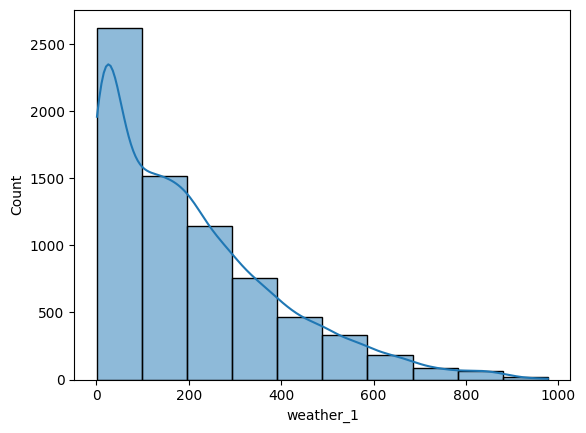

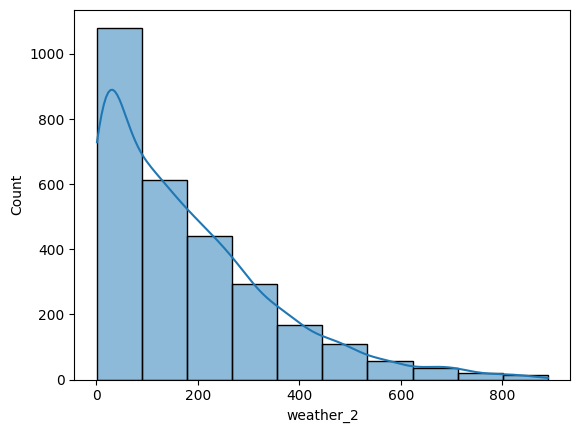

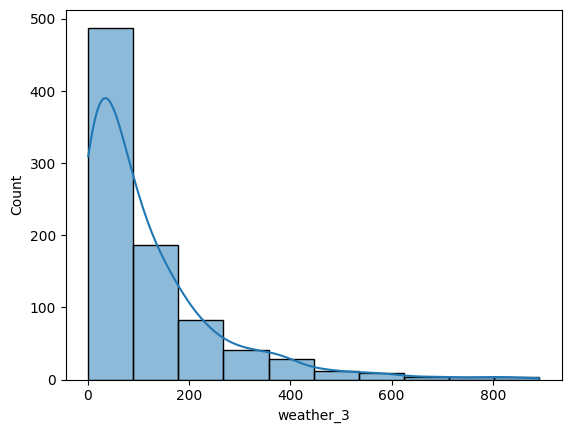

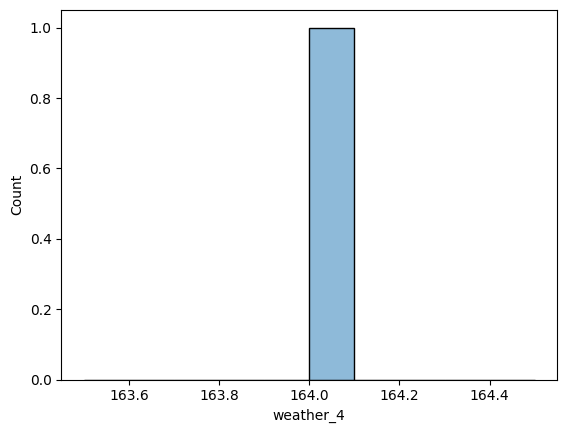

In [82]:
sns.histplot(weather_1,bins=10,kde=True)
plt.xlabel("weather_1")
plt.show()
sns.histplot(weather_2,bins=10,kde=True)
plt.xlabel("weather_2")
plt.show()
sns.histplot(weather_3,bins=10,kde=True)
plt.xlabel("weather_3")
plt.show()
sns.histplot(weather_4,bins=10,kde=True)
plt.xlabel("weather_4")
plt.show()

In [83]:
# check QQ plot for weathers

((array([-3.72833929, -3.49851474, -3.37211613, ...,  3.37211613,
          3.49851474,  3.72833929]),
  array([  1,   1,   1, ..., 968, 970, 977])),
 (np.float64(177.50256264984543),
  np.float64(205.23679087875414),
  np.float64(0.9439766522111215)))

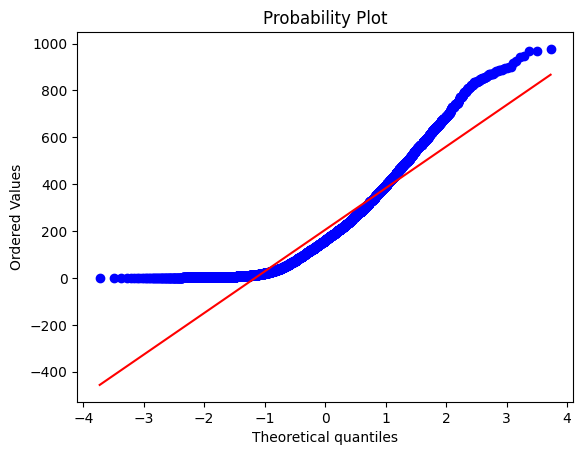

In [84]:
probplot(weather_1,dist="norm",plot=plt)

((array([-3.48665304, -3.24193409, -3.10655043, ...,  3.10655043,
          3.24193409,  3.48665304]),
  array([  1,   1,   1, ..., 862, 868, 890])),
 (np.float64(157.82398189829604),
  np.float64(178.95553987297103),
  np.float64(0.9365111227539789)))

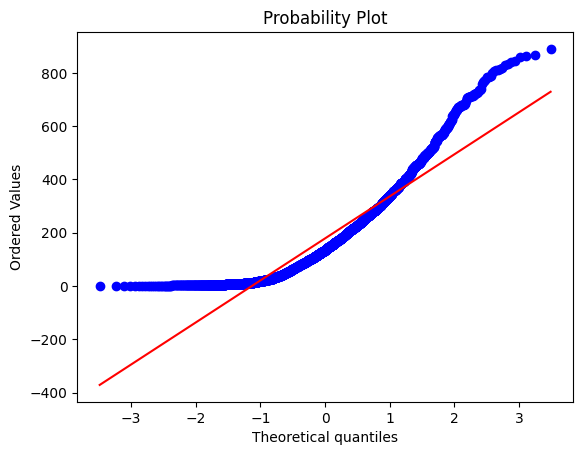

In [85]:
probplot(weather_2,dist="norm",plot=plt)

((array([-3.15351022e+00, -2.88487573e+00, -2.73473867e+00, -2.62873620e+00,
         -2.54596596e+00, -2.47765538e+00, -2.41925857e+00, -2.36810459e+00,
         -2.32248602e+00, -2.28124285e+00, -2.24354983e+00, -2.20879820e+00,
         -2.17652562e+00, -2.14637240e+00, -2.11805300e+00, -2.09133684e+00,
         -2.06603496e+00, -2.04199045e+00, -2.01907160e+00, -1.99716669e+00,
         -1.97618014e+00, -1.95602951e+00, -1.93664316e+00, -1.91795847e+00,
         -1.89992032e+00, -1.88247997e+00, -1.86559409e+00, -1.84922398e+00,
         -1.83333494e+00, -1.81789569e+00, -1.80287800e+00, -1.78825624e+00,
         -1.77400710e+00, -1.76010930e+00, -1.74654338e+00, -1.73329147e+00,
         -1.72033714e+00, -1.70766524e+00, -1.69526176e+00, -1.68311374e+00,
         -1.67120915e+00, -1.65953679e+00, -1.64808625e+00, -1.63684781e+00,
         -1.62581238e+00, -1.61497147e+00, -1.60431710e+00, -1.59384180e+00,
         -1.58353853e+00, -1.57340067e+00, -1.56342198e+00, -1.55359659e+00,

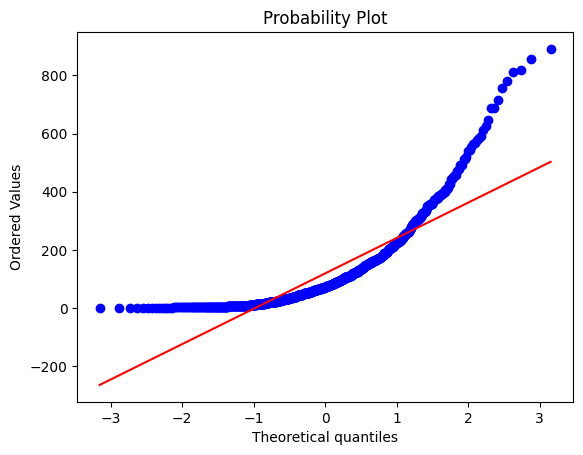

In [86]:
probplot(weather_3,dist="norm",plot=plt)

/usr/local/lib/python3.13/dist-packages/scipy/stats/_morestats.py:640: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  slope, intercept, r, prob, _ = _stats_py.linregress(osm, osr)


((array([0.]), array([164])),
 (np.float64(nan), np.float64(nan), np.float64(nan)))

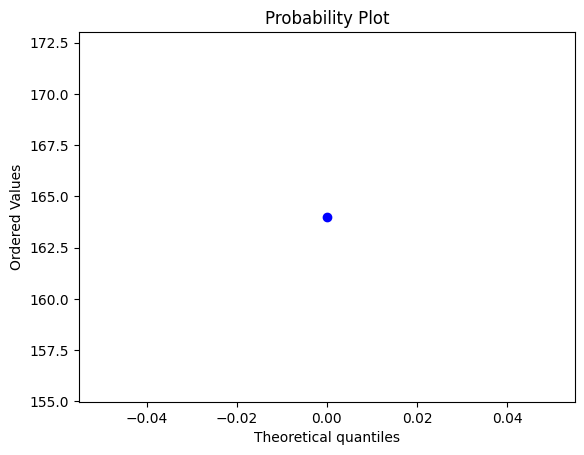

In [87]:
probplot(weather_4,dist="norm",plot=plt)

In [88]:
#  check normality using shapiro wilk test

In [89]:
test_stats,p_value=shapiro(weather_1)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7192.
  res = hypotest_fun_out(*samples, **kwds)


In [90]:
test_stats,p_value=shapiro(weather_2)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [91]:
test_stats,p_value=shapiro(weather_3)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [92]:
test_stats,p_value=shapiro(weather_4)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

Not to reject the null hypothesis


/tmp/ipykernel_1176/2419363827.py:1: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  test_stats,p_value=shapiro(weather_4)


In [93]:
test_stats,p_value=levene(weather_1,weather_2,weather_3,weather_4)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [94]:
#  both normality and variance test are not exist then we use kruskal wallis test instead of using anova

In [95]:
# H0= there is no significance difference between season_1,season_2,season_3,season_4 of no. of rented the cycle
# H1= there is  significance difference between season_1,season_2,season_3,season_4 of no. of rented the cycle

In [96]:
test_stats,p_value=kruskal(weather_1,weather_2,weather_3,weather_4)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [97]:
data=pd.DataFrame({"value":list(weather_1)+list(weather_2)+list(weather_3)+list(weather_4),
                  "group":(["weather_1"]*len(weather_1)+["weather_2"]*len(weather_2)+["weather_3"]*len(weather_3)+["weather_4"]*len(weather_4))})

In [98]:
result=sp.posthoc_dunn(data,val_col="value",group_col="group",p_adjust="bonferroni")
result

,weather_1,weather_2,weather_3,weather_4
weather_1,1.000000e+00,3.786847e-07,1.019009e-43,1.0
weather_2,3.786847e-07,1.000000e+00,2.766733e-22,1.0
weather_3,1.019009e-43,2.766733e-22,1.000000e+00,1.0
weather_4,1.000000e+00,1.000000e+00,1.000000e+00,1.0


In [99]:
alpha = 0.05

for i in range(len(result.columns)):
    for j in range(i + 1, len(result.columns)):
        p_adj = result.iloc[i, j]

        if p_adj < alpha:
            print(
                result.columns[i],
                "vs",
                result.columns[j],
                ": Significant, adjusted p-value =", p_adj
            )
        else:
            print(
                result.columns[i],
                "vs",
                result.columns[j],
                ": Not significant, adjusted p-value =", p_adj)

weather_1 vs weather_2 : Significant, adjusted p-value = 3.7868471931927506e-07
weather_1 vs weather_3 : Significant, adjusted p-value = 1.0190093717099805e-43
weather_1 vs weather_4 : Not significant, adjusted p-value = 1.0
weather_2 vs weather_3 : Significant, adjusted p-value = 2.7667331816569604e-22
weather_2 vs weather_4 : Not significant, adjusted p-value = 1.0
weather_3 vs weather_4 : Not significant, adjusted p-value = 1.0


In [100]:
# Weather is dependent on season (check between 2 predictor variable)

In [101]:
table=pd.crosstab(df["weather"],df["season"])

In [102]:
table

season,1,2,3,4
weather,,,,
1,1759,1801,1930,1702
2,715,708,604,807
3,211,224,199,225
4,1,0,0,0


In [103]:
#  H0= there is no significance difference between weather and seasons
#  H1= there is significance difference between weather and seasons

In [104]:
from scipy.stats import chi2_contingency

In [105]:
chi2_contingency(table)
p_value
alpha=0.05
if p_value<alpha:
  print("reject the null hypothesis")
else:
  print("Not to reject the null hypothesis")

reject the null hypothesis


In [106]:
# H1= there is significance difference between weather and seasons

In [107]:
# Demand planning: Use the observed differences across weather conditions and seasons to guide bike availability and operational planning.



# Working-day strategy: Compare demand on working and non-working days before changing fleet distribution or pricing.



# Weather-based operations: Investigate whether unfavorable weather is associated with lower demand, and plan maintenance and vehicle availability accordingly.



# Further analysis: Explore hourly and weekday patterns to identify peak-demand periods.